# Dar_019 — Spatial connectivity of lunar environmental diagnostics

**Objective:** environmental evidence for choosing a lunar base location together with terrain. This follows the original notebooks 31–32 diagnostic/comparison/interpretation flow, without changing their code, CNN artifacts or protected reserves.

## Questions and prior evidence

- Q01: How much native terrain/illumination context is finite on the declared analysis grids?
- Q02: How often do solar, Earth and slope conditions co-occur on the raster lattice?
- Q03: How many connected diagnostic zones exist, and what is the largest nominal projected extent?
- Q04: Are joint samples isolated single cells or parts of larger components?
- Q05: How sensitive is connectivity to four- versus eight-neighbour adjacency?
- Q06: How do 60, 120 and 240 m analysis lattices change the apparent result?
- Q07: Does shifting the 60 m lattice by half a cell change the result?
- Q08: Do zones touch the analysis boundary, and what do interior-distance proxies suggest?

Read the accepted Dar_017/018 results before interpreting these extensions. The questions are related diagnostics, not independent experiments.

## Input contract and declared considerations

GRID_CASES, cuts and adjacency are declared before results. Containing-native-pixel lookups decode source scales once; 60 m is an analysis lattice, not newly measured resolution. Compare 60/120/240 m and a 30 m shift, four/eight neighbours, and all 27 cut combinations. Only complete projected analysis cells inside the original seven rectangles are retained. Unknown context is a barrier, not a favourable fill. Nominal projected area and center-distance diameter proxies do not prove buildability, geodesic area, physical co-registration or minimum width.

In [1]:
from pathlib import Path
import sys,json
from itertools import product
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0]=[str(ROOT/'darrel stuff/EDA'),str(ROOT)]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from environment_workflow import LocalRun as Run,latest_completed_run
from decision_eda import accepted_input
from environmental_selection_eda import *
import environmental_selection_eda as methods
DATA=ROOT/'darrel stuff/data'
REGION_LIMIT=None  # Set 1 for the initial representative sample, None for all seven.
JOINT_RUN_ID='20261106T134155791814Z_c6f9ab'
joint=latest_completed_run(ROOT,'analysis/dar_012_joint_environment',JOINT_RUN_ID)
def savefig(run,fig,name):
    fig.savefig(run.path(name+'.png'),dpi=125,bbox_inches='tight');display(fig);plt.close(fig)
def register_methods(run):
    run.input(Path(methods.__file__))
    for name in ['moon_p1_analysis.py','site_comparison.py','decision_eda.py']:
        run.input(ROOT/'darrel stuff/EDA'/name)
    for name in ['31_vertical_scale_sensitivity.ipynb','32_candidate_coverage_and_ranking.ipynb']:
        run.input(ROOT/'notebooks/modeling/terrain_similarity'/name)
def publish(run,record):
    run.path('findings.json').write_text(json.dumps(record,indent=2,default=str),encoding='utf-8')
    display(record)
def selected_regions(values):
    regions=sorted(values)
    if REGION_LIMIT is not None:
        if type(REGION_LIMIT) is not int or not 1<=REGION_LIMIT<=len(regions):raise ValueError('Invalid region sample')
        regions=regions[:REGION_LIMIT]
    return regions

Accepted local analysis/dar_012_joint_environment run: 20261106T134155791814Z_c6f9ab


## Build a new local run and compare the data

Inputs and helper source hashes are recorded. Results remain under `darrel stuff/data/processed/analysis/`; source downloads and earlier notebooks are not overwritten.

Accepted local analysis/dar_001_temperature_local_time run: 20261106T082643415392Z_4e6a0b
Accepted local analysis/dar_002_temperature_environment run: 20261106T082929336242Z_623f9f


A3CLR22_10_Leibnitz_Beta_Plateau 60.0 0.0 cells 70756


A3CLR22_10_Leibnitz_Beta_Plateau 120.0 0.0 cells 17424


A3CLR22_10_Leibnitz_Beta_Plateau 240.0 0.0 cells 4356


A3CLR22_10_Leibnitz_Beta_Plateau 60.0 30.0 cells 70756


A3CLR22_11_Malapert_Massif 60.0 0.0 cells 121801


... (19 outputs left out)

A3CLR22_5_Connecting_Ridge_Extension 60.0 0.0 cells 110224


A3CLR22_5_Connecting_Ridge_Extension 120.0 0.0 cells 27556


A3CLR22_5_Connecting_Ridge_Extension 240.0 0.0 cells 6724


A3CLR22_5_Connecting_Ridge_Extension 60.0 30.0 cells 110889


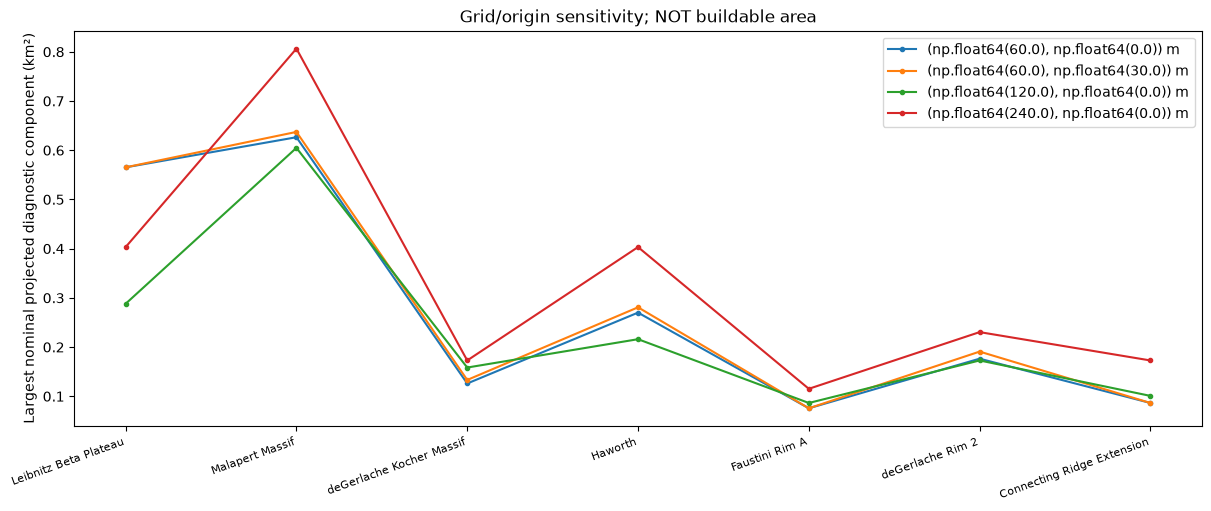

,region,joint_cells,component_count,largest_nominal_projected_area_m2,singleton_components,lattice_interior_diameter_proxy_m
26,A3CLR22_10_Leibnitz_Beta_Plateau,869,160,565200.0,65,208.328157
242,A3CLR22_11_Malapert_Massif,1373,192,626400.0,86,208.328157
458,A3CLR22_12_deGerlache_Kocher_Massif,274,46,126000.0,17,180.000000
674,A3CLR22_2_Haworth,367,79,270000.0,51,279.411255
890,A3CLR22_3_Faustini_Rim_A,117,30,75600.0,13,109.705627
1106,A3CLR22_4_deGerlache_Rim_2,576,129,176400.0,69,208.328157
1322,A3CLR22_5_Connecting_Ridge_Extension,227,62,86400.0,34,180.000000


**Observed influence:** the same joint-condition mask fragments into multiple spatial zones. Compare grid/origin and adjacency controls before treating a component as footprint evidence; the projected extent does not establish buildability.

{'questions': ['Q01', 'Q02', 'Q03', 'Q04', 'Q05', 'Q06', 'Q07', 'Q08'],
 'regions': 7,
 'sweep_rows': 1512,
 'candidate_examples': 21,
 'primary_grid_summary': [{'analysis_cells': 70756,
   'finite_joint_cells': 70756,
   'unknown_joint_cells': 0,
   'joint_cells': 869,
   'joint_sample_fraction': 0.012281643959522867,
   'component_count': 160,
   'largest_component_cells': 157,
   'largest_nominal_projected_area_m2': 565200.0,
   'largest_component_share_of_joint': 0.1806674338319908,
   'singleton_components': 65,
   'lattice_interior_diameter_proxy_m': 208.32815729997475,
   'connectivity': 4,
   'solar_min': 0.5,
   'earth_min': 0.5,
   'slope_max_deg': 10.0,
   'diagnostic_only': True,
   'components_with_diameter_proxy_ge_120m': 4,
   'components_with_diameter_proxy_ge_240m': 0,
   'components_with_diameter_proxy_ge_480m': 0,
   'region': 'A3CLR22_10_Leibnitz_Beta_Plateau',
   'spacing_m': 60.0,
   'shift_m': 0.0},
  {'analysis_cells': 121801,
   'finite_joint_cells': 121801,
  

In [2]:
thermal=latest_completed_run(ROOT,'analysis/dar_001_temperature_local_time','20261106T082643415392Z_4e6a0b')
environment=latest_completed_run(ROOT,'analysis/dar_002_temperature_environment','20261106T082929336242Z_623f9f')
layers=source_layers(DATA)
GRID_CASES=[(60.,0.),(120.,0.),(240.,0.),(60.,30.)]
THRESHOLDS=list(product([.25,.5,.75],[.25,.5,.75],[5.,10.,15.]))
ILLUSTRATION=(.5,.5,10.)
with Run(ROOT,'analysis/dar_019_spatial_environment',{'region_limit':REGION_LIMIT,'grid_cases':GRID_CASES,
    'diagnostic_thresholds':THRESHOLDS,'illustration':ILLUSTRATION,'connectivities':[4,8],
    'candidate_examples_per_region':3,'source_environment_run':str(environment.relative_to(ROOT)),
    'operational_policy_adopted':False},'Moon/Site_Assessment/Dar_019_spatial_environment_connectivity.ipynb') as run:
    register_methods(run)
    footprints=json.loads(accepted_input(run,thermal,'region_footprints.json').read_text())
    source_manifest=json.loads((environment/'provenance.json').read_text());run.input(environment/'provenance.json')
    for definition in layers.values():
        for key in ['path','label']:
            if key not in definition:continue
            path=definition[key];run.input(path)
            identity=str(path.relative_to(ROOT))
            if run.record['inputs'][identity]['sha256']!=source_manifest['inputs'][identity]['sha256']:
                raise ValueError('Raw source changed since accepted Dar_002: '+identity)
    summaries=[];component_tables=[];candidates=[];source_support=[];grid_metas={}
    regions=selected_regions(footprints)
    for region in regions:
        bounds=footprints[region]['bounds_m']
        for spacing,shift in GRID_CASES:
            cells,meta=lattice(bounds,spacing,shift);cells,support=sample_layers(layers,cells,bounds)
            cells['region']=region
            support['region']=region;support['spacing_m']=spacing;support['shift_m']=shift;source_support.append(support)
            for thresholds in THRESHOLDS:
                for connectivity in [4,8]:
                    detailed=thresholds==ILLUSTRATION
                    labels,table,summary=components(cells,meta,thresholds,connectivity,detail=detailed)
                    summary.update(region=region,spacing_m=spacing,shift_m=shift);summaries.append(summary)
                    if detailed:
                        table['region']=region;table['spacing_m']=spacing;table['shift_m']=shift;table['connectivity']=connectivity
                        component_tables.append(table)
                        if spacing==60 and shift==0 and connectivity==4:
                            tagged,examples=select_component_candidates(cells,labels,table,region)
                            examples['selection']='three largest four-connected components under diagnostic (0.5,0.5,10); not best bases'
                            candidates.append(examples)
                            tagged.to_csv(run.path('grids/'+region+'.csv.gz'),index=False,compression={'method':'gzip','mtime':0})
                            grid_metas[region]=meta
                            np.save(run.path('labels/'+region+'.npy'),labels)
            print(region,spacing,shift,'cells',len(cells))
    summary=pd.DataFrame(summaries);candidate_manifest=pd.concat(candidates,ignore_index=True)
    summary.to_csv(run.path('connectivity_threshold_grid_sweep.csv'),index=False)
    pd.concat(component_tables,ignore_index=True).to_csv(run.path('illustrative_component_catalog.csv'),index=False)
    candidate_manifest.to_csv(run.path('diagnostic_candidate_manifest.csv'),index=False)
    pd.concat(source_support,ignore_index=True).to_csv(run.path('native_source_grid_support.csv'),index=False)
    run.path('grid_metadata.json').write_text(json.dumps(grid_metas,indent=2),encoding='utf-8')
    benchmark=summary.loc[summary.solar_min.eq(.5)&summary.earth_min.eq(.5)&summary.slope_max_deg.eq(10)]
    benchmark.to_csv(run.path('illustrative_grid_connectivity_comparison.csv'),index=False)
    fig,ax=plt.subplots(figsize=(12,5),layout='constrained')
    for key,p in benchmark.loc[benchmark.connectivity.eq(4)].groupby(['spacing_m','shift_m']):
        p=p.set_index('region').reindex(regions)
        ax.plot(range(len(regions)),p.largest_nominal_projected_area_m2/1e6,marker='.',label=str(key)+' m')
    ax.set_xticks(range(len(regions)),[x.split('_',2)[-1].replace('_',' ') for x in regions],rotation=20,ha='right',fontsize=8)
    ax.set(ylabel='Largest nominal projected diagnostic component (km²)',title='Grid/origin sensitivity; NOT buildable area');ax.legend()
    savefig(run,fig,'connectivity_grid_sensitivity')
    full=benchmark.loc[benchmark.spacing_m.eq(60)&benchmark.shift_m.eq(0)&benchmark.connectivity.eq(4)]
    display(full[['region','joint_cells','component_count','largest_nominal_projected_area_m2','singleton_components','lattice_interior_diameter_proxy_m']])
    display(Markdown('**Observed influence:** the same joint-condition mask fragments into multiple spatial zones. Compare grid/origin and adjacency controls before treating a component as footprint evidence; the projected extent does not establish buildability.'))
    publish(run,{'questions':['Q%02d'%i for i in range(1,9)],'regions':len(regions),'sweep_rows':len(summary),
        'candidate_examples':len(candidate_manifest),'primary_grid_summary':full.to_dict('records'),
        'limits':['Nominal projected lattice area is not geodesic or buildable area','Technical CRS agreement does not establish physical co-registration',
                  'Interior diameter is a discretization proxy, not proven minimum site width','No minimum footprint size or operational threshold adopted']})
OUT=run.directory

## Findings and observed influence

Read the executed `findings.json`, tables and plots above; counts and missing groups are part of the result. An observed rank/availability change is sensitivity under the declared controls, not evidence that the changed setting is correct.

## Effect on hard rules and soft preferences

Connected-zone diagnostics can inform an explicitly specified footprint requirement later. Solar/Earth/slope cuts here are not hard limits. Larger components can be a stated preference, not an automatic base score. Preserve grid/origin/adjacency sensitivity and boundary flags.

## Implementation handoff and next decision

Reuse the functions in `../../environmental_selection_eda.py` and retain source/assessment-unit contracts. Compare available evidence before adopting any rule. See [EDA work plan and questions](../../EDA_Notes.md#eda-question-register), [EDA results](../../EDA_Results.md) and [the proposal](../../../Brief_Overview.md#algorithm-proposal) for the full EDA → influence → proposed implementation chain. Exact CNN-patch matching remains optional; local, regional and reference evidence must not be conflated.

## Save reusable data and disposable reports

The completed run above already saved reusable tables, plots, `findings.json` and provenance together. Later notebooks read accepted table exports rather than notebook display outputs. Clear/regenerate disposable reports only if intended; no source data were deleted.